# SEATTLE WEATHER PROJECT

## INTRODUCTION

Seattle, Washington is known for being a very rainy city but is it true? In this project, I will compare the daily precipitation between Seattle, Washington and Spokane, Washington to see if Seattle in facts rains more often. 

The project uses the daily weather data from 2018 through 2022. First, I will inspect and preprocess the data, then I will compare the precipitation between these 2 cities by summary statistics and visualization. Then I will examine the differences between months and also compare how often each city rains. 

Finally, I will use statistical hypothesis testing to determine if there is a significant difference between Seattle and Spokane. The objective of this project is to use the data science methodology to help answer whether Seattle gets more rainfall than Spokane. 


## DATA SOURCE

The weather data used in this project comes from the National Oceanic and Atmospheric Administration (NOAA) through its National Centers for Environmental Information (NCEI) Climate Data Online (CDO) system. NOAA's Climate Data Online provides access to historical weather and climate data, including daily precipitation measurements.
The data for this project contains daily precipitation measurements for Seattle and Spokane from January 1, 2018 through December 31, 2022. The Seattle observations are associated with the Seattle area, while the Spokane observations are from Spokane.
The original weather data was cleaned and combined into the clean_seattle_spokane_weather.csv file used in this notebook. 

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn as a data visualization library built on matplotlib
import seaborn as sns

Exploratory data analysis

In [62]:
df = pd.read_csv ("/Users/linhchung/Desktop/DATA 5100 copy/Project 1/weather/code/clean_seattle_spokane_weather.csv")

## Daily precipitation graph

First, I will visualize the daily precipitation for Seattle and Spokane on the same graph. This will show me how precipitation changes over time and either of the cities has higher precipitation than the other. 

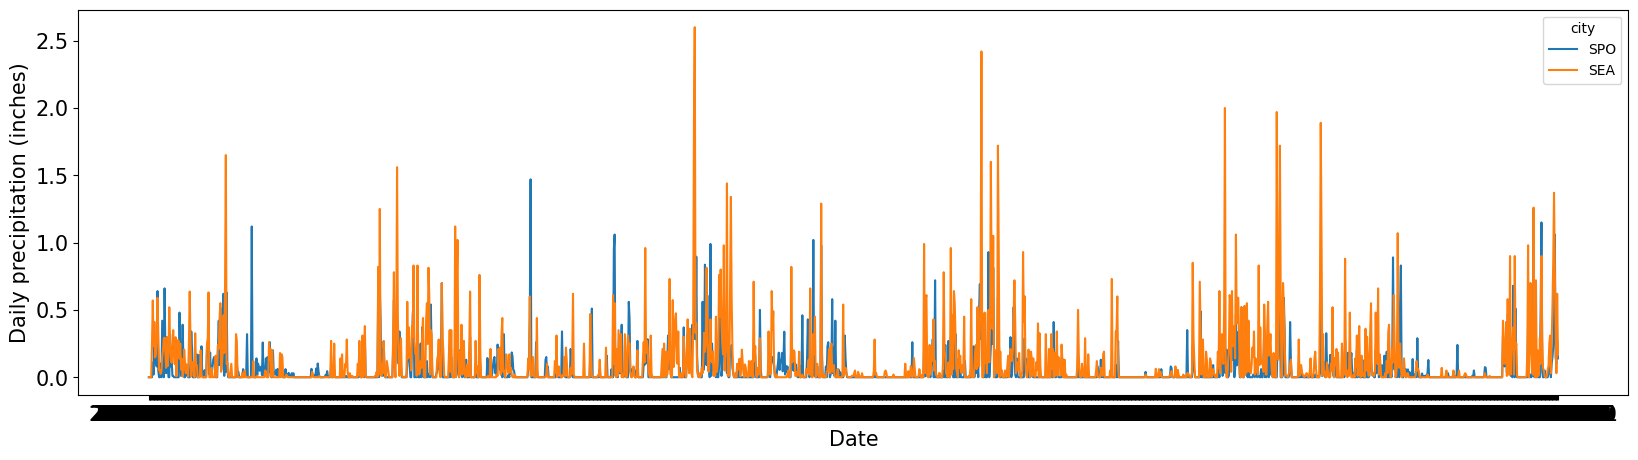

In [65]:
plt.figure(figsize=(20, 5))

sns.lineplot(data=df, x='date', y='precipitation', hue='city')

plt.xlabel('Date', fontsize=15)
plt.ylabel('Daily precipitation (inches)', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

Looking at the graph I can see that the precipitation changes from day to day in both cities. Generally, Seattle has higher precipitation values than Spokane. However, there are many days when the two cities have very similar precipitation, or some days when Spokane receives more precipitation. It also shows there are some parts of the year that the precipitation appears to be higher than others. 

## Compute basic numerical summaries for precipitation in each city

Here I will calculate descriptive statistics for precipitation in each city. They include the number of observations, mean, standard deviation, minimum, quartiles, and maximum. It gives a numerical summary of the precipitation data before going into details of the comparison between 2 cities. 

In [67]:
df[['city', 'precipitation']].groupby('city').describe()

precipitation                                                
             count      mean       std  min  25%   50%   75%   max
city                                                              
SEA         1795.0  0.113593  0.242201  0.0  0.0  0.01  0.12  2.60
SPO         1795.0  0.064314  0.148688  0.0  0.0  0.00  0.06  1.47

We can see that the descriptive statistics show that Seattle has a higher average daily precipitation than Spokane. Seattle’s mean of daily precipitation is approximately 0.114 inches, while Spokane’s is approximately 0.064. Also, Seattle has a higher maximum daily precipitation. 

On the other hand, the median precipitation is much lower than the mean for both cities. This shows that some days with large amounts of precipitation increase the average. 


## Compare mean precipitation values averaged over all days

I will calculate the mean daily precipitation for each city to compare directly between the 2 cities. The average amount of precipitation recorded on a day during the study period is presented by the mean. 

In [144]:
df[['city', 'precipitation']].groupby('city').mean()

,precipitation
city,
SEA,0.113593
SPO,0.064314


As the result, Seattle got more precipitation on an average day than Spokane in 5 years. Seattle received about 0.050 more inches of precipitation per day on average, according to the mean. I will examine this difference further using visualization and statistical tests. 

## Show the values as a bar graph

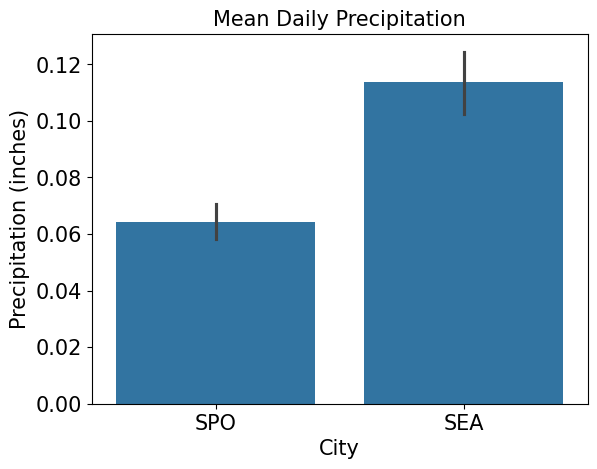

In [74]:
sns.barplot(data=df, x='city', y='precipitation')

plt.ylabel('Precipitation (inches)', fontsize=15)
plt.xlabel('City', fontsize=15)
plt.title('Mean Daily Precipitation', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

With this bar graph, the difference between the 2 cities is very clear. The Seattle’s bar is higher than the Spokane’s bar. This is consistent with the numerical means shown above. 

## Precipitation by month

Comparing only the overall averages might diminish seasonal patterns since precipitation can change significantly throughout the year. To compare the precipitation across 12 months, I will create a month variable from the date column. 

In [77]:
df['month'] = pd.DatetimeIndex(df['date']).month

To verify that if the month variable was added correctly and that the existing data remain intact, I will inspect the first few rows of the DataFrame. 

In [79]:
df.head()

,date,city,precipitation,day_of_year,month
0,2018-01-01,SPO,0.0,1,1
1,2018-01-02,SPO,0.0,2,1
2,2018-01-03,SPO,0.0,3,1
3,2018-01-04,SPO,0.0,4,1
4,2018-01-05,SPO,0.0,5,1


It shows that the month variable was successfully added to the DataFrame.  

To confirm that all 12 months are represented in the dataset, I will check the unique values in the month column. 

In [81]:
df['month'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12], dtype=int32)

The output contains month values from 1 through 12, confirming that all twelve months are represented in the dataset.

## Plot the distribution of precipitation amounts each month using boxplots

I will use boxplots to compare the distribution of precipitation amounts each month for Seattle and Spokane.

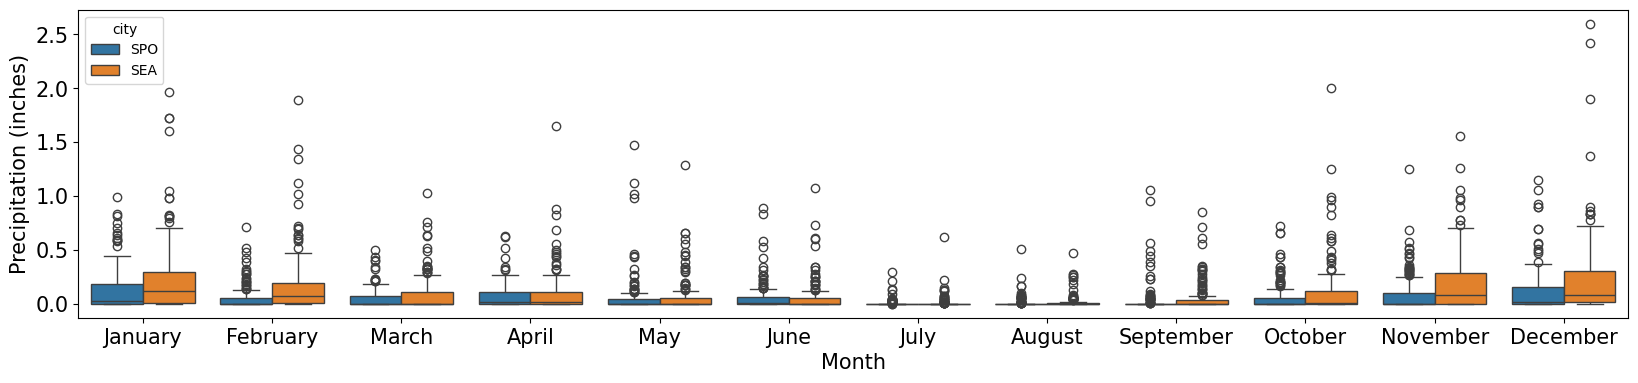

In [84]:
plt.figure(figsize=(20, 4))

sns.boxplot(data=df, x='month', y='precipitation', hue='city')

plt.xlabel('Month', fontsize=15)
plt.ylabel('Precipitation (inches)', fontsize=15)

plt.tick_params(labelsize=15)

import calendar
month_names = list(calendar.month_name[1:]) 
plt.xticks(ticks=range(12), labels=month_names) 

plt.show()

The boxplots show clear seasonal patterns in precipitation. Both cities generally have higher precipitation during the cooler months and lower precipitation during the summer. Seattle generally has higher precipitation distributions than Spokane, particularly during the wetter months.

## Orient the plot horizontally

The horizontal version presents the same monthly distributions in a different orientation. This makes it easier to compare the range and spread of precipitation values within each month.

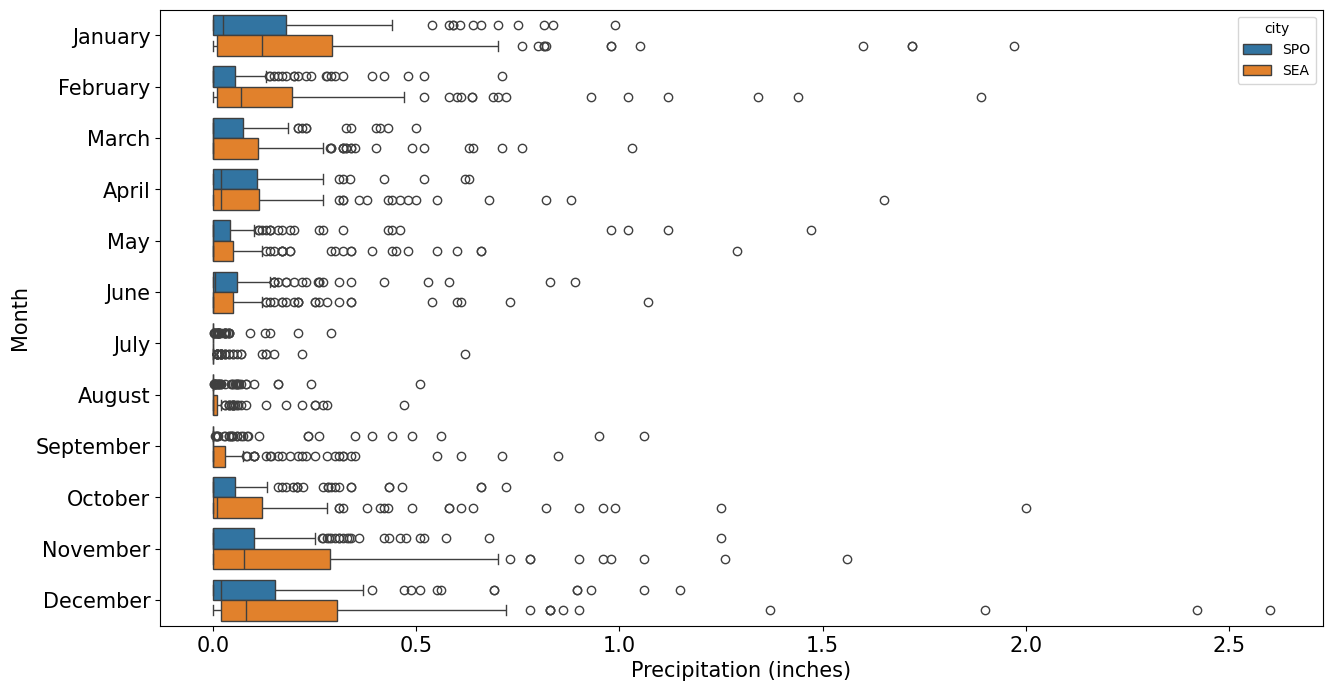

In [87]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=df, x='precipitation', y='month', hue='city', orient='h')

plt.ylabel('Month', fontsize=15)
plt.xlabel('Precipitation (inches)', fontsize=15)

plt.tick_params(labelsize=15)

plt.yticks(ticks=range(12), labels=month_names)

plt.show()

## Zoom in on the precipitation axis

I am limiting the precipitation axis to 0.4 inches to make the differences among the typical daily precipitation values easier to see. Very large precipitation values are excluded from the visible portion of the graph, but they remain in the dataset and are still included in the calculations.

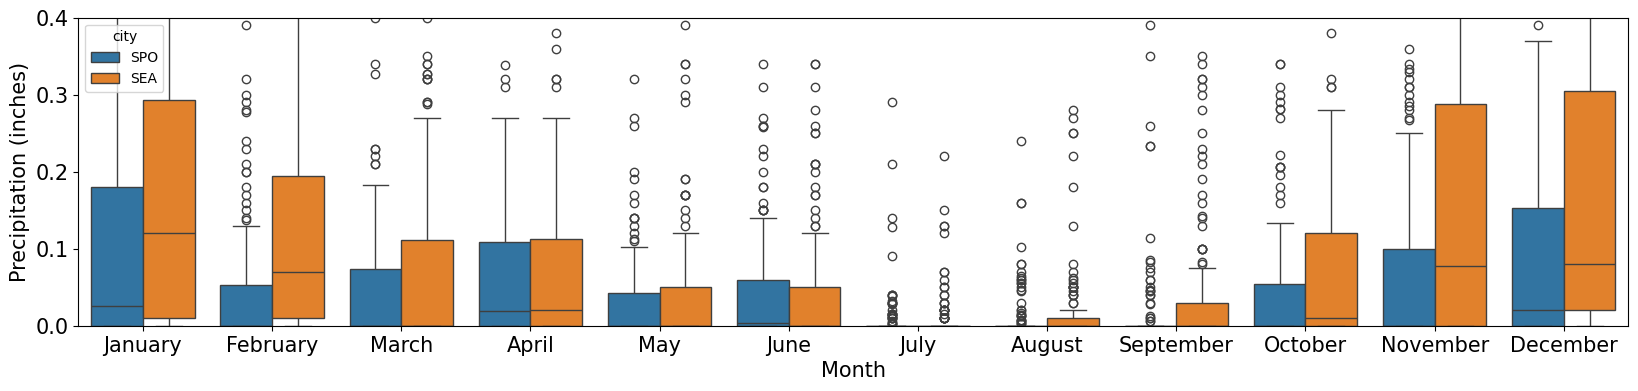

In [90]:
plt.figure(figsize=(20, 4))

sns.boxplot(data=df, x='month', y='precipitation', hue='city')

plt.xlabel('Month', fontsize=15)
plt.ylabel('Precipitation (inches)', fontsize=15)

plt.tick_params(labelsize=15)

plt.xticks(ticks=range(12), labels=month_names)

plt.ylim(0, 0.4)

plt.show()

## Plot the mean precipitation each month

Next, I will compare the mean daily precipitation for each month and city. This will show which months contribute most to the overall precipitation differences between Seattle and Spokane.

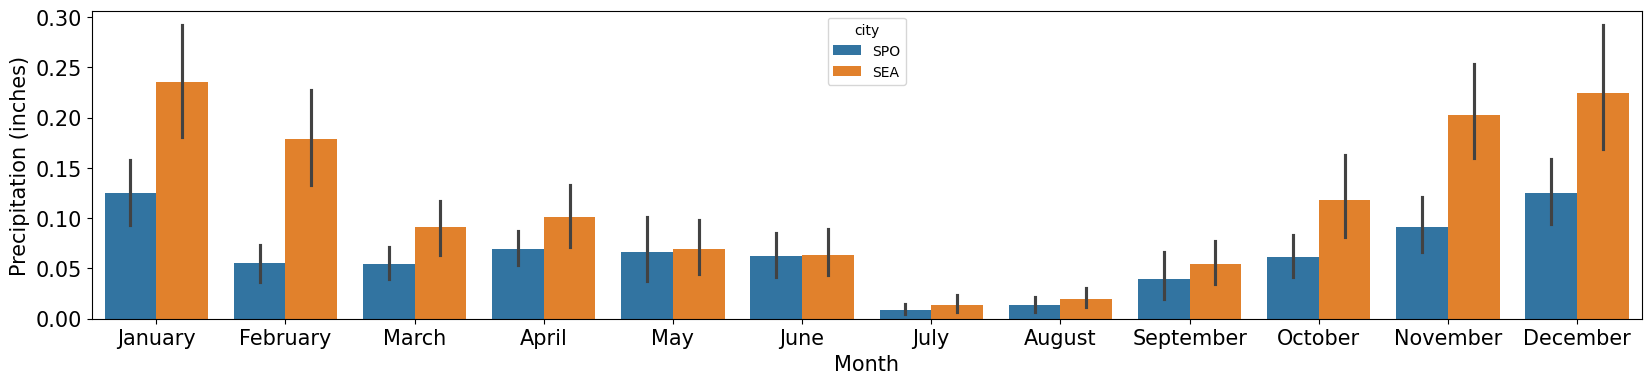

In [93]:
plt.figure(figsize=(20, 4))

sns.barplot(data=df, x='month', y='precipitation', hue='city')

plt.xlabel('Month', fontsize=15)
plt.ylabel('Precipitation (inches)', fontsize=15)

plt.tick_params(labelsize=15)

plt.xticks(ticks=range(12), labels=month_names)

plt.show()

The graph shows that the largest differences generally occur during the wetter months. Seattle has noticeably higher mean precipitation than Spokane during January, February, March, October, November, and December. During the summer months, the two cities have much smaller differences.

## Compute the mean precipitation each month

The monthly means provide the numerical values behind the previous visualization. Comparing these values allows me to identify the months in which Seattle and Spokane have the largest differences in average daily precipitation.

In [96]:
df[['month', 'precipitation', 'city']].groupby(['city', 'month']).mean()

precipitation
city month               
SEA  1           0.235101
     2           0.178795
     3           0.091087
     4           0.100743
     5           0.069161
     6           0.063503
     7           0.013833
     8           0.019995
     9           0.054284
     10          0.118452
     11          0.202923
     12          0.224903
SPO  1           0.125484
     2           0.055456
     3           0.054673
     4           0.069591
     5           0.065897
     6           0.062697
     7           0.009157
     8           0.013392
     9           0.039491
     10          0.061200
     11          0.090940
     12          0.124645

The results show that January has one of the largest differences, with Seattle averaging about 0.235 inches of daily precipitation compared with about 0.125 inches in Spokane. February and November also show substantial differences. In contrast, the average precipitation in June and July is very similar between the two cities.

## Plot the proportion of days with any precipitation

The amount of precipitation is only one way to compare the cities. A city could receive more total precipitation because of a few very large storms, even if it does not rain more frequently. To examine precipitation frequency, I will create a Boolean variable called any_precipitation. It will be True when precipitation is greater than zero and False when there is no precipitation.

In [99]:
df['any_precipitation'] = df['precipitation'] > 0

In [101]:
df.head()

,date,city,precipitation,day_of_year,month,any_precipitation
0,2018-01-01,SPO,0.0,1,1,False
1,2018-01-02,SPO,0.0,2,1,False
2,2018-01-03,SPO,0.0,3,1,False
3,2018-01-04,SPO,0.0,4,1,False
4,2018-01-05,SPO,0.0,5,1,False


The new variable classifies each observation as either a day with precipitation or a day without precipitation. This will allow me to compare how frequently precipitation occurs in Seattle and Spokane.

## Plot the proportion of days with any precipitation over the 5 years

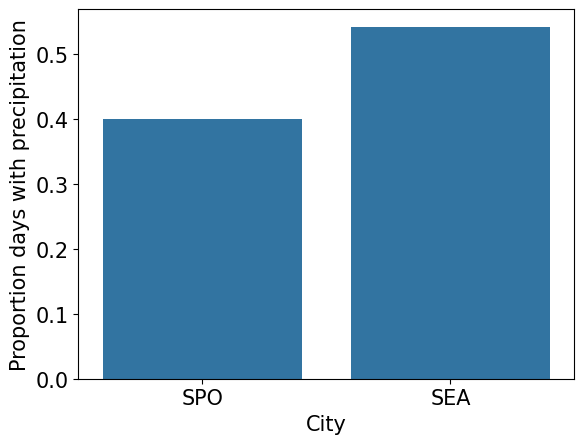

In [174]:
sns.barplot(data=df, x='city', y='any_precipitation', errorbar=None)

plt.xlabel('City', fontsize=15)
plt.ylabel('Proportion days with precipitation', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

Seattle had precipitation on more than 50% of the days in the dataset, while Spokane had precipitation on around 40% of the days.

This means precipitation occurred on a larger proportion of days in Seattle. Therefore, Seattle differs from Spokane not only in average daily precipitation but also in how frequently precipitation occurred.

## Plot the proportion of days with precipitation each month

I will now examine the proportion of days with precipitation for each month. This will show whether the difference in precipitation frequency between Seattle and Spokane changes throughout the year.

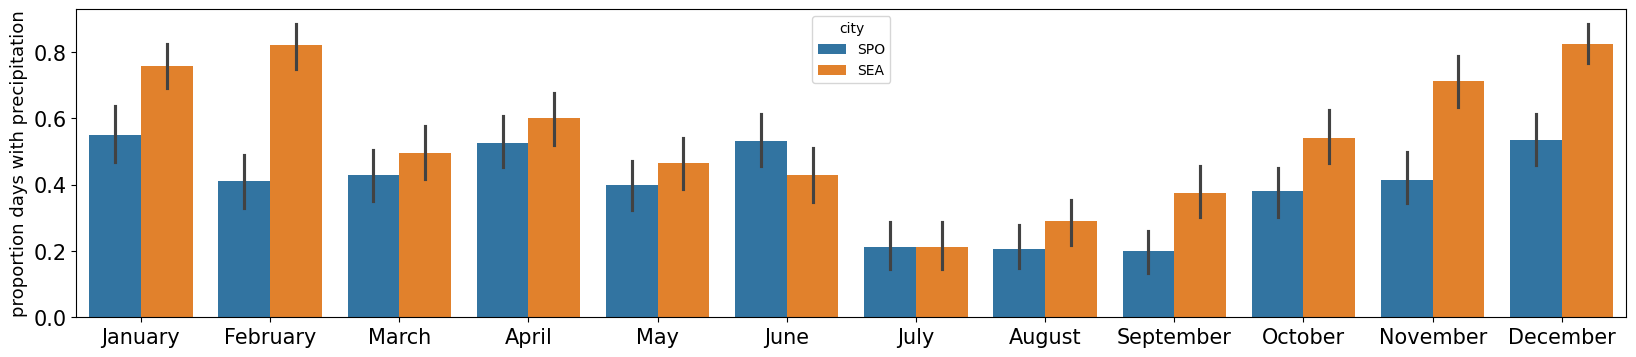

In [107]:
plt.figure(figsize=(20, 4))

sns.barplot(data=df, x='month', y='any_precipitation', hue='city')

plt.xlabel(None)
plt.ylabel('proportion days with precipitation', fontsize=13)
plt.xticks(ticks=range(12), labels=month_names)
plt.tick_params(labelsize=15)

plt.show()

The monthly results show that the frequency of precipitation varies by season. Seattle generally has a higher proportion of days with precipitation during the wetter months, while the difference between the cities becomes smaller during the summer.

# Analysis

## Perform a statistical test for differences in the mean precipitation each month between the cities

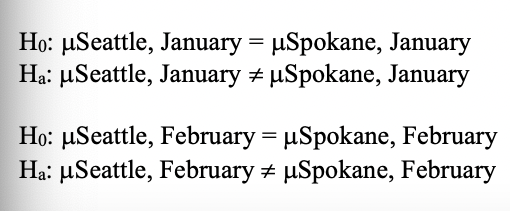



Descriptive statistics and visualizations indicate that Seattle receives more precipitation than Spokane. However, differences in sample means can happen by chance, so I'll use statistical hypothesis tests to see if the observed differences are statistically significant.

I'll run two types of tests. First, I'll compare the average daily precipitation in Seattle and Spokane for each month. Second, I'll compare the proportion of days with precipitation between the two cities for each month.

For these tests, I will set a significance level of 0.05. A p-value less than 0.05 will be interpreted as evidence of a statistically significant difference between the cities.

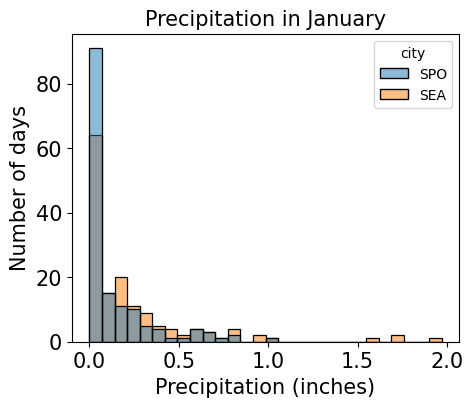

In [64]:
plt.figure(figsize=(5, 4))

sns.histplot(data=df.loc[df['month'] == 1], x='precipitation', hue='city')

plt.xlabel('Precipitation (inches)', fontsize=15)
plt.ylabel('Number of days', fontsize=15)
plt.title('Precipitation in January', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

## Testing Differences in Mean Precipitation

I will use an independent two-sample t-test for each month to compare the mean daily precipitation between Seattle and Spokane. The null hypothesis for each month is that the two cities have the same mean precipitation. The alternative hypothesis is that their mean precipitation values are different.

I will use a significance level of 0.05. If the p-value is less than 0.05, I will consider the difference statistically significant.

In [111]:
from scipy import stats

In [113]:
significance_level = 0.05
significantly_different = np.zeros(12)

#Perform t-test for each month

for month in range (1, 13):
    # Get precipitation data for Seattle and Spokane for the current month
    sea_data = df.loc[(df['city'] == 'SEA') & (df['month'] == month), 'precipitation']
    stl_data = df.loc[(df['city'] == 'SPO') & (df['month'] == month), 'precipitation']

    t_statistic, p_value = stats.ttest_ind(sea_data, stl_data, equal_var=False)

    if p_value < significance_level:
        significantly_different[month-1] = 1

    print(f"Month {month}:")
    print(f" t-statistic = {t_statistic:.2f}")
    print(f" p-value t test = {p_value:.3f}")
    print("-" * 20)


Month 1:
 t-statistic = 3.33
 p-value t test = 0.001
--------------------
Month 2:
 t-statistic = 4.54
 p-value t test = 0.000
--------------------
Month 3:
 t-statistic = 2.31
 p-value t test = 0.022
--------------------
Month 4:
 t-statistic = 1.64
 p-value t test = 0.102
--------------------
Month 5:
 t-statistic = 0.16
 p-value t test = 0.874
--------------------
Month 6:
 t-statistic = 0.05
 p-value t test = 0.961
--------------------
Month 7:
 t-statistic = 0.85
 p-value t test = 0.396
--------------------
Month 8:
 t-statistic = 1.03
 p-value t test = 0.304
--------------------
Month 9:
 t-statistic = 0.92
 p-value t test = 0.356
--------------------
Month 10:
 t-statistic = 2.45
 p-value t test = 0.015
--------------------
Month 11:
 t-statistic = 4.00
 p-value t test = 0.000
--------------------
Month 12:
 t-statistic = 2.86
 p-value t test = 0.005
--------------------


The t-tests show statistically significant differences in mean precipitation during January, February, March, October, November, and December, because their p-values are below 0.05.

For example, January has a p-value of approximately 0.001, indicating a statistically significant difference in mean precipitation between the cities. In contrast, the differences in April through September are not statistically significant at the 0.05 level.

These results suggest that Seattle's higher precipitation is particularly pronounced during the wetter part of the year.

## Plot the mean precipitation each month with a star for significant differences

I will add a star to the months where the t-test found a statistically significant difference in mean precipitation. This makes it easier to identify the months where the difference between Seattle and Spokane is supported by the statistical test.

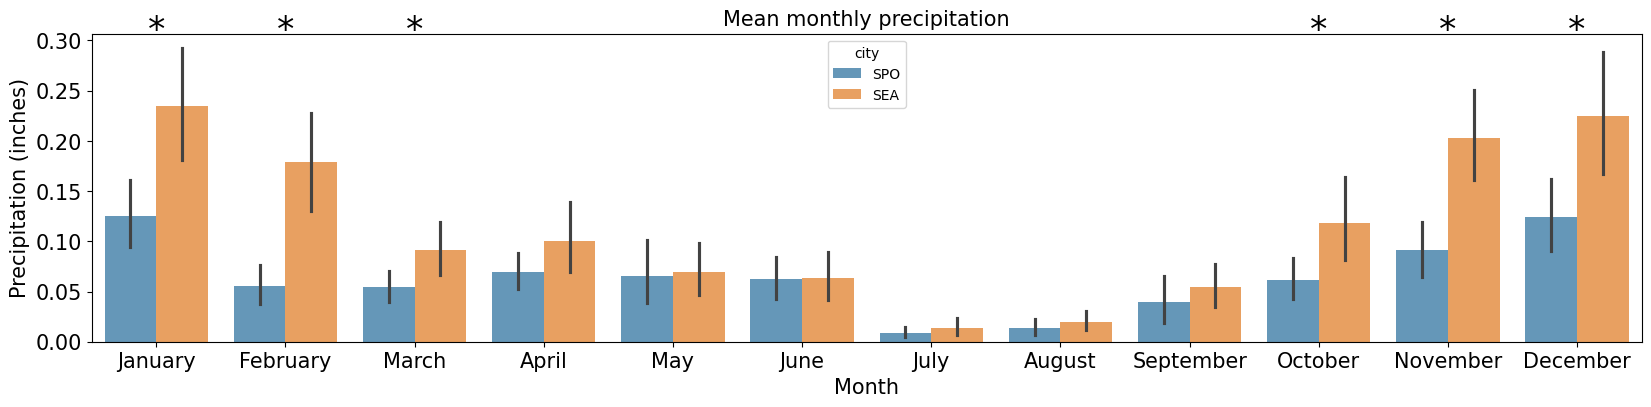

In [116]:
plt.figure(figsize=(20, 4))

sns.barplot(data=df, x='month', y='precipitation', hue='city', alpha=0.75)

plt.xlabel('Month', fontsize=15)
plt.ylabel('Precipitation (inches)', fontsize=15)
plt.title('Mean monthly precipitation', fontsize=15)

plt.tick_params(labelsize=15)

plt.xticks(ticks=range(12), labels=month_names)

#Add stars for significantly different months
for month in range (12):
    if significantly_different[month]==1:

        #Add a star:
        plt.text(month, 0.3, '*', ha='center', fontsize=25)

plt.show()

The stars identify the months with statistically significant differences in mean precipitation. The significant months are concentrated in the wetter part of the year, while the summer months generally do not show statistically significant differences.

## Perform a statistical test for differences in the proportion of days with any precipitation each month between the cities

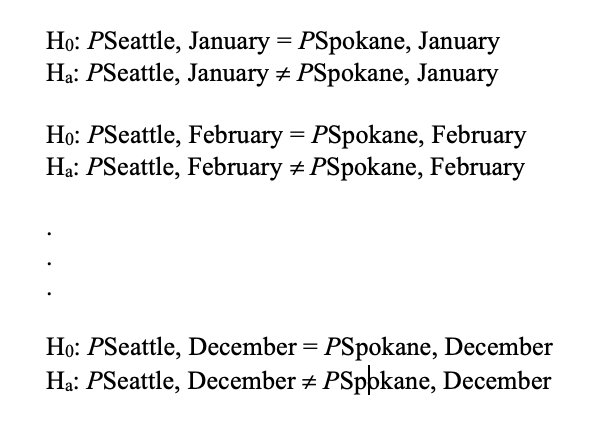

The previous test compared the amount of precipitation on each day. I will now test whether Seattle and Spokane differ in the proportion of days with any precipitation.

For each month, I will use a two-proportion z-test. The null hypothesis is that Seattle and Spokane have the same proportion of days with precipitation. The alternative hypothesis is that the proportions are different.

As before, I will use a significance level of 0.05.

In [119]:
from statsmodels.stats.proportion import proportions_ztest

significane_level = 0.05
significantly_different_proportion = np.zeros(12)

#Perform t-test for each month
for month in range (1,13):
    #Create a contigency table for Seattle and Spokane for the current month:
    contigency_table = pd.crosstab(
        df.loc[df['month'] == month, 'city'], df.loc[df['month'] == month, 'any_precipitation']
    )

    #Calculate the number of True values (days with precipitation) for each city
    days_with_precipitation = contigency_table[True]

    #Calculate the total number of days for each city
    total_counts = contigency_table.sum(axis=1)

    #Hypothesis test
    zstat, p_value = proportions_ztest(
        count=days_with_precipitation, nobs=total_counts, alternative='two-sided'

    )

    if p_value < significance_level:
        significantly_different_proportion[month-1]=1

    print(f"Month {month};")
    print(f" z-statistic = {zstat:.2f}")
    print(f" p-value =  {p_value:.3f}")
    print("-" * 20)
        

        

Month 1;
 z-statistic = 3.78
 p-value =  0.000
--------------------
Month 2;
 z-statistic = 7.03
 p-value =  0.000
--------------------
Month 3;
 z-statistic = 1.15
 p-value =  0.249
--------------------
Month 4;
 z-statistic = 1.29
 p-value =  0.197
--------------------
Month 5;
 z-statistic = 1.15
 p-value =  0.252
--------------------
Month 6;
 z-statistic = -1.75
 p-value =  0.080
--------------------
Month 7;
 z-statistic = 0.00
 p-value =  1.000
--------------------
Month 8;
 z-statistic = 1.71
 p-value =  0.087
--------------------
Month 9;
 z-statistic = 3.32
 p-value =  0.001
--------------------
Month 10;
 z-statistic = 2.85
 p-value =  0.004
--------------------
Month 11;
 z-statistic = 5.03
 p-value =  0.000
--------------------
Month 12;
 z-statistic = 5.48
 p-value =  0.000
--------------------


The proportion tests show statistically significant differences in the frequency of precipitation during January, February, September, October, November, and December. These months have p-values below 0.05.

For example, the p-value for December is very small, indicating strong evidence that the proportion of days with precipitation differs between Seattle and Spokane. In contrast, the differences during March through August are not statistically significant at the 0.05 level.

Overall, these results support the conclusion that Seattle experiences precipitation more frequently than Spokane, especially during the wetter months.

## Examining the January Counts

Finally, I will display the contingency table for January to see the actual number of days with and without precipitation in each city. The table provides the counts used to calculate the proportions in the statistical test.

In [121]:
contingency_table = pd.crosstab(
    df.loc[df['month'] == 1, 'city'], df.loc[df['month'] == 1, 'any_precipitation']
)
contingency_table

any_precipitation,False,True
city,,
SEA,36,113
SPO,67,82


The January contingency table shows that Seattle had 113 days with precipitation and 36 days without precipitation, while Spokane had 82 days with precipitation and 67 days without precipitation.

This corresponds to a higher proportion of precipitation days in Seattle and helps explain the statistically significant difference found by the proportion test for January.